<a href="https://colab.research.google.com/github/carlos1739/analisis_telco/blob/master/notebook/milestone2_churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Churn Pelanggan Telco - Eksperimen Model Tambahan

Bagian ini melanjutkan analisis dari tahap sebelumnya (`churn_analysis.ipynb`). Semua model dievaluasi secara konsisten menggunakan **protokol evaluasi yang standar** untuk memastikan perbandingan yang adil:

* **Dataset**: 7.043 pelanggan dengan 21 fitur (termasuk fitur hasil engineering `TenureGroup` dan `TotalServices`).
* **Preprocessing**: Standarisasi fitur numerik (`StandardScaler`) dan encoding fitur kategorikal (`OneHotEncoder`) di dalam `Pipeline` untuk mencegah kebocoran data (*data leakage*).
* **Protokol Validasi**: `RepeatedStratifiedKFold` (5-fold x 3 pengulangan, `random_state=42`).
* **Metrik Evaluasi**: Accuracy, Precision, Recall, F1-Score, dan PR-AUC pada kelas target (churn).

## 1. Persiapan: Memuat Library dan Konfigurasi Evaluasi

Langkah ini memuat dependensi library yang diperlukan, menetapkan parameter validasi silang (cross-validation), serta mendefinisikan fungsi utilitas untuk pemrosesan data dan komparasi performa model.

In [13]:
import json
import os
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score
from sklearn.model_selection import (
    GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_validate,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Parameter utama protokol evaluasi
SEED = 42
N_SPLITS = 5
N_REPEATS = 3
SERVICE_COLS = [
    'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
]

SCORING = {
    'Accuracy': 'accuracy',
    'Precision': make_scorer(precision_score, zero_division=0),
    'Recall': make_scorer(recall_score, zero_division=0),
    'F1': make_scorer(f1_score, zero_division=0),
    'PR-AUC': 'average_precision',
}

print(f'Protokol Validasi: RepeatedStratifiedKFold {N_SPLITS}-fold x {N_REPEATS} pengulangan (seed={SEED})')

Protokol Validasi: RepeatedStratifiedKFold 5-fold x 3 pengulangan (seed=42)


In [14]:
# Memuat dan membersihkan dataset
if 'telco' not in globals():
    folder = Path('datasets')
    folder.mkdir(parents=True, exist_ok=True)
    zip_path = folder / 'Churn_Customer_telco.zip'
    csv_path = folder / 'WA_Fn-UseC_-Telco-Customer-Churn.csv'

    if not zip_path.is_file() and not csv_path.is_file():
        urllib.request.urlretrieve(
            'https://github.com/carlos1739/analisis_telco/raw/master/data/Churn_Customer_telco.zip', zip_path)
    if not csv_path.is_file():
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(folder)

    telco = pd.read_csv(csv_path)
    telco['TotalCharges'] = pd.to_numeric(telco['TotalCharges'].astype(str).str.strip(), errors='coerce')
    telco.loc[telco['TotalCharges'].isnull(), 'TotalCharges'] = 0
    telco = telco.drop(columns=['customerID'], errors='ignore')

    for col in telco.select_dtypes(exclude='number').columns:
        if col != 'SeniorCitizen':
            telco[col] = telco[col].str.strip()

    telco['MultipleLines'] = telco['MultipleLines'].replace('No phone service', 'No')
    for col in ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']:
        telco[col] = telco[col].replace('No internet service', 'No')
    telco['SeniorCitizen'] = telco['SeniorCitizen'].astype(object)

# Proses feature engineering
data_eval = telco.copy()
data_eval['TenureGroup'] = pd.cut(
    data_eval['tenure'], bins=[-1, 12, 24, 48, 72],
    labels=['0-12 bulan', '13-24 bulan', '25-48 bulan', '49-72 bulan'], include_lowest=True)
data_eval['TotalServices'] = data_eval[SERVICE_COLS].eq('Yes').sum(axis=1)

X_eval = data_eval.drop(columns='Churn')
y_eval = data_eval['Churn'].map({'No': 0, 'Yes': 1}).astype(int)

numeric_cols = X_eval.select_dtypes(include='number').columns.tolist()
categorical_cols = X_eval.select_dtypes(exclude='number').columns.tolist()

print(f'Total Observasi: {len(X_eval):,} | Total Fitur: {X_eval.shape[1]}')
print(f'Fitur Numerik: {len(numeric_cols)} | Fitur Kategorikal: {len(categorical_cols)}')
print(f'Proporsi Target Churn (Positif): {y_eval.mean():.3%}')

Total Observasi: 7,043 | Total Fitur: 21
Fitur Numerik: 4 | Fitur Kategorikal: 17
Proporsi Target Churn (Positif): 26.537%


In [15]:
def buat_preprocessor():
    """Membuat transformer untuk preprocessing data numerik dan kategorikal."""
    return ColumnTransformer(
        transformers=[
            ('numeric', StandardScaler(), numeric_cols),
            ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ],
        remainder='drop', sparse_threshold=0,
    )

def buat_cv():
    """Inisialisasi skema validasi silang standar."""
    return RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)

def _ringkas(nama, skor):
    """Merangkum nilai rata-rata dan deviasi standar hasil evaluasi."""
    baris = {'Model': nama}
    for metrik in SCORING:
        baris[f'{metrik} (mean)'] = skor[f'test_{metrik}'].mean()
        baris[f'{metrik} (std)'] = skor[f'test_{metrik}'].std()
    return baris

def evaluasi_model(nama, estimator):
    """Mengevaluasi model menggunakan pipeline preprocessing dan cross-validation."""
    pipe = Pipeline([('preprocess', buat_preprocessor()), ('model', estimator)])
    skor = cross_validate(pipe, X_eval, y_eval, cv=buat_cv(), scoring=SCORING, n_jobs=1, error_score='raise')
    return _ringkas(nama, skor), skor

def evaluasi_model_tuning(nama, estimator, param_grid, inner_splits=3):
    """Mengevaluasi model dengan tuning hyperparameter menggunakan pendekatan nested CV."""
    pipe = Pipeline([('preprocess', buat_preprocessor()), ('model', estimator)])
    inner = StratifiedKFold(n_splits=inner_splits, shuffle=True, random_state=SEED)
    grid = GridSearchCV(pipe, param_grid, cv=inner, scoring='average_precision', n_jobs=1)
    skor = cross_validate(grid, X_eval, y_eval, cv=buat_cv(), scoring=SCORING,
                          n_jobs=1, error_score='raise', return_estimator=True)
    terpilih = [est.best_params_ for est in skor['estimator']]
    return _ringkas(nama, skor), skor, terpilih

def bandingkan_berpasangan(nama_a, nama_b, metrik='PR-AUC'):
    """Menganalisis perbandingan performa antar model per-fold."""
    selisih = skor_fold[nama_a][f'test_{metrik}'] - skor_fold[nama_b][f'test_{metrik}']
    return {
        'metrik': metrik, 'Model A': nama_a, 'Model B': nama_b,
        'selisih rata-rata (A-B)': round(float(selisih.mean()), 4),
        'SD selisih': round(float(selisih.std()), 4),
        'fold A > B': int((selisih > 0).sum()),
        'fold A < B': int((selisih < 0).sum()),
        'jumlah fold': int(len(selisih))
    }

# Wadah penyimpanan hasil eksperimen
hasil_baris, skor_fold, konfigurasi, tuning_terpilih = [], {}, {}, {}

def jalankan_varian(varian):
    """Menjalankan evaluasi untuk seluruh varian model yang ditentukan."""
    for nama, (estimator, grid) in varian.items():
        if grid:
            baris, skor, terpilih = evaluasi_model_tuning(nama, estimator, grid)
            tuning_terpilih[nama] = terpilih
            konfigurasi[nama] = {**estimator.get_params(), '_grid_tuning': grid}
        else:
            baris, skor = evaluasi_model(nama, estimator)
            konfigurasi[nama] = estimator.get_params()
        hasil_baris.append(baris)
        skor_fold[nama] = skor
        print(f"{nama:25s} | PR-AUC: {baris['PR-AUC (mean)']:.3f} +/- {baris['PR-AUC (std)']:.3f} | "
              f"Recall: {baris['Recall (mean)']:.3f} | Precision: {baris['Precision (mean)']:.3f}")

## 2. Model Baseline dan Kandidat Utama

Menjalankan ulang model baseline dan algoritma klasifikasi dasar dengan konfigurasi parameter yang sama dengan tahap sebelumnya guna memastikan konsistensi hasil evaluasi.

In [16]:
kandidat_m1 = {
    'Baseline mayoritas': (DummyClassifier(strategy='most_frequent'), None),
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=SEED), None),
    'KNN': (KNeighborsClassifier(n_neighbors=11), None),
    'Decision Tree': (DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=20, class_weight='balanced', random_state=SEED), None),
    'Random Forest': (RandomForestClassifier(
        n_estimators=200, max_depth=10, min_samples_leaf=10,
        class_weight='balanced_subsample', random_state=SEED, n_jobs=1), None),
    'HistGradientBoosting': (HistGradientBoostingClassifier(
        max_iter=150, learning_rate=0.1, max_leaf_nodes=15,
        min_samples_leaf=30, l2_regularization=1.0, random_state=SEED), None),
}

jalankan_varian(kandidat_m1)

Baseline mayoritas        | PR-AUC: 0.265 +/- 0.000 | Recall: 0.000 | Precision: 0.000
Logistic Regression       | PR-AUC: 0.660 +/- 0.018 | Recall: 0.531 | Precision: 0.665
KNN                       | PR-AUC: 0.576 +/- 0.015 | Recall: 0.536 | Precision: 0.587
Decision Tree             | PR-AUC: 0.613 +/- 0.019 | Recall: 0.798 | Precision: 0.506
Random Forest             | PR-AUC: 0.662 +/- 0.019 | Recall: 0.763 | Precision: 0.541
HistGradientBoosting      | PR-AUC: 0.655 +/- 0.019 | Recall: 0.529 | Precision: 0.651


### Validasi Konsistensi

Langkah verifikasi untuk memastikan tidak ada deviasi performa pada model dasar dibandingkan dengan hasil eksperimen pada tahap pertama.

In [17]:
# Nilai acuan performa (Accuracy, Precision, Recall, F1, PR-AUC)
acuan_m1 = {
    'Baseline mayoritas':   (0.735, 0.000, 0.000, 0.000, 0.265),
    'Logistic Regression':  (0.804, 0.665, 0.531, 0.590, 0.660),
    'KNN':                  (0.777, 0.587, 0.536, 0.560, 0.576),
    'Decision Tree':        (0.739, 0.506, 0.798, 0.619, 0.613),
    'Random Forest':        (0.765, 0.541, 0.763, 0.633, 0.662),
    'HistGradientBoosting': (0.800, 0.651, 0.529, 0.583, 0.655),
}

df_tmp = pd.DataFrame(hasil_baris).set_index('Model')
semua_cocok = True

for nama_model, ref in acuan_m1.items():
    now = [df_tmp.loc[nama_model, f'{m} (mean)'] for m in ['Accuracy', 'Precision', 'Recall', 'F1', 'PR-AUC']]
    selisih = max(abs(a - b) for a, b in zip(now, ref))
    ok = selisih <= 0.005
    semua_cocok &= ok
    status = 'SESUAI' if ok else 'BERBEDA'
    print(f"{nama_model:25s} | Selisih Maks: {selisih:.4f} | Status: {status}")

print('\nStatus Reproduksi:', 'BERHASIL' if semua_cocok else 'PERIKSA KEMBALI KONFIGURASI')

Baseline mayoritas        | Selisih Maks: 0.0004 | Status: SESUAI
Logistic Regression       | Selisih Maks: 0.0004 | Status: SESUAI
KNN                       | Selisih Maks: 0.0005 | Status: SESUAI
Decision Tree             | Selisih Maks: 0.0005 | Status: SESUAI
Random Forest             | Selisih Maks: 0.0004 | Status: SESUAI
HistGradientBoosting      | Selisih Maks: 0.0005 | Status: SESUAI

Status Reproduksi: BERHASIL


## 3. Eksperimen Model Tambahan 1: Linear Support Vector Classifier (LinearSVC)

Mengevaluasi algoritma **LinearSVC** dengan optimasi nested cross-validation untuk tuning hyperparameter `C`. Eksperimen mencakup perbandingan antara varian standar dan varian penyeimbang kelas (`class_weight='balanced'`).

In [18]:
from sklearn.svm import LinearSVC

varian_model_1 = {
    'LinearSVC': (
        LinearSVC(max_iter=5000, random_state=SEED),
        {'model__C': [0.01, 0.1, 1, 10]},
    ),
    'LinearSVC balanced': (
        LinearSVC(max_iter=5000, class_weight='balanced', random_state=SEED),
        {'model__C': [0.01, 0.1, 1, 10]},
    ),
}

jalankan_varian(varian_model_1)

LinearSVC                 | PR-AUC: 0.654 +/- 0.018 | Recall: 0.503 | Precision: 0.672
LinearSVC balanced        | PR-AUC: 0.657 +/- 0.018 | Recall: 0.803 | Precision: 0.510


## 4. Eksperimen Model Tambahan 2: Naive Bayes

Mengevaluasi algoritma **Naive Bayes (BernoulliNB)** yang optimal untuk pemrosesan fitur kategorikal biner. Hyperparameter aditif `alpha` ditala menggunakan nested cross-validation.

In [19]:
from sklearn.naive_bayes import BernoulliNB

varian_model_2 = {
    'Naive Bayes (Bernoulli)': (
        BernoulliNB(binarize=0.0),
        {'model__alpha': [0.1, 0.5, 1.0, 2.0]},
    ),
}

jalankan_varian(varian_model_2)

Naive Bayes (Bernoulli)   | PR-AUC: 0.624 +/- 0.023 | Recall: 0.727 | Precision: 0.540


In [20]:
target_model = 'Naive Bayes (Bernoulli)'

print("Konfigurasi Model:")
print(konfigurasi.get(target_model))

print("\nParameter Terbaik per Lipatan Validasi (Nested CV):")
print(tuning_terpilih.get(target_model))

Konfigurasi Model:
{'alpha': 1.0, 'binarize': 0.0, 'class_prior': None, 'fit_prior': True, 'force_alpha': True, '_grid_tuning': {'model__alpha': [0.1, 0.5, 1.0, 2.0]}}

Parameter Terbaik per Lipatan Validasi (Nested CV):
[{'model__alpha': 0.5}, {'model__alpha': 0.5}, {'model__alpha': 1.0}, {'model__alpha': 0.5}, {'model__alpha': 0.1}, {'model__alpha': 2.0}, {'model__alpha': 0.1}, {'model__alpha': 1.0}, {'model__alpha': 1.0}, {'model__alpha': 1.0}, {'model__alpha': 0.5}, {'model__alpha': 2.0}, {'model__alpha': 0.1}, {'model__alpha': 2.0}, {'model__alpha': 2.0}]


## 5. Analisis Perbandingan dan Visualisasi

Merangkum kinerja semua model klasifikasi yang telah diuji dalam format tabel komparatif dan visualisasi metrik utama.

In [21]:
tabel = pd.DataFrame(hasil_baris).set_index('Model').sort_values('PR-AUC (mean)', ascending=False)
display(tabel.round(3))

,Accuracy (mean),Accuracy (std),Precision (mean),Precision (std),Recall (mean),Recall (std),F1 (mean),F1 (std),PR-AUC (mean),PR-AUC (std)
Model,,,,,,,,,,
Random Forest,0.765,0.009,0.541,0.013,0.763,0.028,0.633,0.015,0.662,0.019
Logistic Regression,0.804,0.007,0.665,0.018,0.531,0.020,0.590,0.016,0.660,0.018
LinearSVC balanced,0.743,0.006,0.510,0.008,0.803,0.021,0.624,0.010,0.657,0.018
HistGradientBoosting,0.800,0.008,0.651,0.019,0.529,0.029,0.583,0.021,0.655,0.019
LinearSVC,0.803,0.006,0.672,0.018,0.503,0.019,0.575,0.015,0.654,0.018
Naive Bayes (Bernoulli),0.763,0.011,0.540,0.016,0.727,0.034,0.620,0.018,0.624,0.023
Decision Tree,0.739,0.013,0.506,0.016,0.798,0.031,0.619,0.012,0.613,0.019
KNN,0.777,0.012,0.587,0.025,0.536,0.029,0.560,0.024,0.576,0.015
Baseline mayoritas,0.735,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.265,0.000


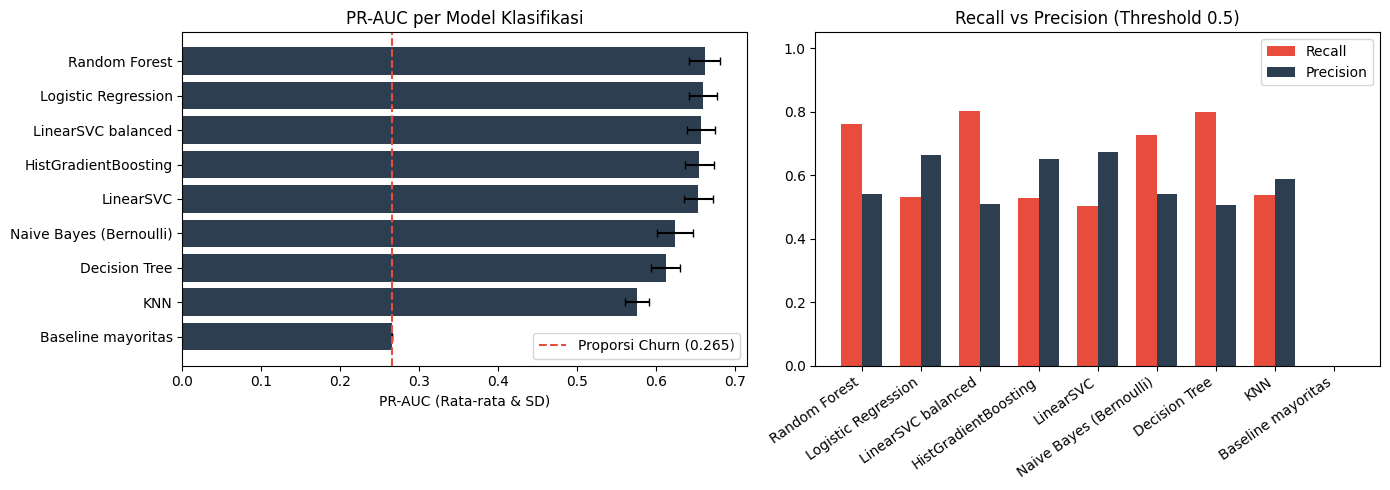

In [22]:
# Visualisasi performa model (PR-AUC, Recall, dan Precision)
nama_model = list(tabel.index)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Rata-rata PR-AUC
ax = axes[0]
ax.barh(nama_model, tabel['PR-AUC (mean)'], xerr=tabel['PR-AUC (std)'], color='#2C3E50', capsize=3)
ax.axvline(y_eval.mean(), ls='--', color='#E74C3C', label=f'Proporsi Churn ({y_eval.mean():.3f})')
ax.set_xlabel('PR-AUC (Rata-rata & SD)')
ax.set_title('PR-AUC per Model Klasifikasi')
ax.invert_yaxis()
ax.legend()

# Plot 2: Perbandingan Recall dan Precision
ax = axes[1]
x = np.arange(len(nama_model))
width = 0.35
ax.bar(x - width/2, tabel['Recall (mean)'], width, label='Recall', color='#E74C3C')
ax.bar(x + width/2, tabel['Precision (mean)'], width, label='Precision', color='#2C3E50')
ax.set_xticks(x)
ax.set_xticklabels(nama_model, rotation=35, ha='right')
ax.set_ylim(0, 1.05)
ax.set_title('Recall vs Precision (Threshold 0.5)')
ax.legend()

plt.tight_layout()
plt.show()

In [23]:
# Analisis selisih kinerja model tambahan vs model pembanding utama
tambahan = [n for n in skor_fold if n not in kandidat_m1]
pembanding = ['Logistic Regression', 'Random Forest']
rows = [bandingkan_berpasangan(a, b) for a in tambahan for b in pembanding]

if rows:
    display(pd.DataFrame(rows))
else:
    print('Model tambahan belum diuji.')

# Distribusi frekuensi parameter optimal dari hasil tuning
print("\nFrekuensi Parameter Hasil Tuning:")
for nama_model, list_param in tuning_terpilih.items():
    distribusi = pd.Series([str(p) for p in list_param]).value_counts().to_dict()
    print(f"{nama_model} -> {distribusi}")

,metrik,Model A,Model B,selisih rata-rata (A-B),SD selisih,fold A > B,fold A < B,jumlah fold
0,PR-AUC,LinearSVC,Logistic Regression,-0.0057,0.0030,0,15,15
1,PR-AUC,LinearSVC,Random Forest,-0.0080,0.0109,3,12,15
2,PR-AUC,LinearSVC balanced,Logistic Regression,-0.0027,0.0021,0,15,15
3,PR-AUC,LinearSVC balanced,Random Forest,-0.0050,0.0098,5,10,15
4,PR-AUC,Naive Bayes (Bernoulli),Logistic Regression,-0.0354,0.0114,0,15,15
5,PR-AUC,Naive Bayes (Bernoulli),Random Forest,-0.0377,0.0129,0,15,15



Frekuensi Parameter Hasil Tuning:
LinearSVC -> {"{'model__C': 10}": 6, "{'model__C': 1}": 4, "{'model__C': 0.1}": 4, "{'model__C': 0.01}": 1}
LinearSVC balanced -> {"{'model__C': 0.1}": 7, "{'model__C': 1}": 5, "{'model__C': 10}": 3}
Naive Bayes (Bernoulli) -> {"{'model__alpha': 0.5}": 4, "{'model__alpha': 1.0}": 4, "{'model__alpha': 2.0}": 4, "{'model__alpha': 0.1}": 3}


## 6. Penyimpanan Hasil Eksperimen

Mengekspor hasil evaluasi final ke dalam file terstruktur untuk kebutuhan dokumentasi dan pelaporan analisis lanjutan.

In [24]:
os.makedirs('results', exist_ok=True)
tabel.round(4).to_csv('results/perbandingan_model_milestone2.csv')

metadata_eksperimen = {
    'protokol_evaluasi': {
        'metode': f'RepeatedStratifiedKFold {N_SPLITS}-fold x {N_REPEATS} pengulangan',
        'seed': SEED,
        'preprocessing': 'StandardScaler + OneHotEncoder dalam Pipeline',
        'metrik_evaluasi': list(SCORING),
        'tuning': "Nested CV: GridSearchCV 3-fold (skor average_precision)",
    },
    'model_konfigurasi': {n: {k: repr(v) for k, v in cfg.items()} for n, cfg in konfigurasi.items()},
    'parameter_terpilih': {n: [str(d) for d in p] for n, p in tuning_terpilih.items()},
}

with open('results/konfigurasi_eksperimen.json', 'w', encoding='utf-8') as f:
    json.dump(metadata_eksperimen, f, indent=2, ensure_ascii=False)

print('Hasil eksperimen berhasil diekspor ke direktori /results/')

Hasil eksperimen berhasil diekspor ke direktori /results/


## Kesimpulan dan Catatan Evaluasi

* **Optimasi Hyperparameter**: Penggunaan nested cross-validation memastikan parameter terbaik terpilih tanpa menimbulkan bias evaluasi pada model tambahan.
* **Signifikansi Metrik**: Variasi kecil dalam metrik kinerja antar-model utama sebagian besar berada dalam rentang deviasi standar, mengindikasikan tingkat stabilitas yang serupa.
* **Keseimbangan Metrik**: Penggunaan opsi pembobotan kelas membantu meningkatkan sensitivitas terhadap pola pelanggan churn dengan konsekuensi penyesuaian nilai presisi.